# Grid Contingency Analysis
## Which single failures hurt the grid? How does a failure spread? 

Import necessary packages.

---

In [81]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn
import pandapower.topology as top
import copy
import pandapower.plotting as plot

In [ ]:
# load benchmark IEEE 14-bus network
net = pn.power_system_test_cases.case14()

# run standard AC power flow
pp.runpp(net)

Establish the N-0 case for the IEEE 14-bus system. This serves as a baseline for comparison for N-K contingencies.

In [83]:
# N-0 case (for comparison)
v_min, v_max, load_max = 0.95, 1.10, 100 # establish thresholds (limits) to evaluate grid, v_max increased to account for higher max bus voltage

# load buses
gen_buses = set(net.gen.bus) | set(net.ext_grid.bus) # id buses connected to generator and external grid, joins them
pq_buses = [bus for bus in net.bus.index if bus not in gen_buses] # keep buses that are not in gen_buses

# calculate S to determine how much power each line carries (reference for setting current limits)
vn = net.bus.vn_kv[net.line.from_bus].values # get the nominal voltage of the bus where each line begins
base_mva = np.sqrt(3) * vn * net.res_line.i_ka.values # 3-phase formula to find apparent power

# calculate new limits (current ratings) for the max value in each voltage group
for voltage_group in (vn > 100, vn < 100):
    max_mva = 1.5 * base_mva[voltage_group].max()
    net.line.loc[voltage_group, "max_i_ka"] = max_mva / (np.sqrt(3) * vn[voltage_group])

pp.runpp(net) # rerun power flow using new limits
# plot.simple_plot(net, plot_loads=True, plot_gens=True)

In [84]:
# check each line against the following conditions: 
# 1. min bus voltage < 0.95 pu
# 2. max bus voltage > 1.10 pu
# 3. number of overloaded > 0
# 4. number of islanded > 0

def check_case(net, n=1.0):
    v = net.res_bus.loc[pq_buses, "vm_pu"] # load buses
    loading = net.res_line["loading_percent"]

    # islanded grid, check separation from main network
    # map = top.create_nxgraph(net) # map all true connections
    # islands = list(top.connected_components(map))
    # n_islands = len(islands)
    n_islanded = len(top.unsupplied_buses(net))

    n_overload = int((loading > load_max).sum())
    violation = n_overload > 0 or v.min() < v_min or v.max() > v_max or n_islanded > 0
    perf_index_v = ((abs(v-1.0)/0.10)**(2*n)).sum() # delta V represents bus voltage deviation from nominal target voltage (1.0 pu)
    perf_index_l = ((loading/100)**(2*n)).sum() # divide by 100 to get ratio
    return {
        "Status": "Violation" if violation else "Pass",
        "Max_Line_Loading_%": loading.max(),
        "Worst_Line": loading.idxmax(), # idxmax() records first occurrence of max value
        "Lines_Overloaded": n_overload,
        "Min_Bus_V_pu": v.min(),
        "Max_Bus_V_pu": v.max(),
        "Islanded_Buses": n_islanded,
        "PI_V": perf_index_v, 
        "PI_L": perf_index_l,
        "PI_Total": perf_index_v + perf_index_l, 
    }

base_row = check_case(net)
base_row["Element"] = "None" # ideally, N-0 case should not have any tripped lines
base_row["Index"] = "N/A"
display(pd.DataFrame([base_row]))

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Element,Index
0,Pass,66.666667,9,0,1.017671,1.06152,0,2.029032,1.68011,3.709142,None,N/A


Define a function to observe cascading failures.

In [85]:
# simulate cascading outages
def sim_cascade(net, load_max, start, start_type="line", loop_lim=len(net.line)):
    net = copy.deepcopy(net)
    # load_max = 100
    tripped = [f"{start_type} {start}"] # record all tripped lines
    getattr(net, start_type).loc[start, "in_service"] = False

    for n in range(loop_lim):
        dead = top.unsupplied_buses(net)
        if len(dead) > 0:
            status = "Blackout (islanded)"
            break
        try: 
            pp.runpp(net)
        except pp.LoadflowNotConverged:
            status = "Blackout (no solution)"
            break

        # loading on active lines
        active_lines = net.line.in_service 
        loading = net.res_line.loc[active_lines, "loading_percent"]

        # exit loop (finish) if grid is stable
        if loading.max() <= load_max:
            status = "Stable"
            break

        # trip most overloaded line and go through another iteration
        max_line_loading = loading.idxmax()
        net.line.loc[max_line_loading, "in_service"] = False 
        tripped.append(f"line {max_line_loading}")

    else:
        status = "loop limit reached"

    dead = top.unsupplied_buses(net)
    lost = net.load.loc[net.load.bus.isin(dead), "p_mw"].sum()

    return {
        "Initial_Element": f"{start_type} {start}",
        "Cascade_Status": status,
        "Sequence": tripped,
        "Total_Tripped": len(tripped),
        "Load_Lost_MW": lost,
    }


Simulate an outage of each line, transformer, and generator. Find any thermal/voltage violations. Tabulate the results.

In [86]:
# define N-1 case
def n1_case(net, elem="line"): # analyze line by default
    net = copy.deepcopy(net)
    rows = []
    table = getattr(net, elem)

    for i in table.index:
        table.loc[i, 'in_service'] = False # simulate a fault/outage at a given transmission line

    # exception handling to manage the result of Newton-Ralphson method
        try:
            pp.runpp(net) # recalculate power flow
            row = check_case(net)
        except pp.LoadflowNotConverged:
            row = {"Status": "Non-convergence"}
        finally:
            table.loc[i, "in_service"] = True # restore the line
        row["Element"] = elem
        row["Index"] = i
        rows.append(row)
    return pd.DataFrame(rows)

# do N-1 analysis for line, transformer, and generator
results = pd.concat([n1_case(net, "line"),
                     n1_case(net, "trafo"),
                     n1_case(net, "gen")], ignore_index=True)
display(results)

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Element,Index
0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241,line,0
1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485,line,1
2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291,line,2
3,Pass,69.809807,9,0,1.007096,1.056367,0,1.748227,1.879580,3.627807,line,3
4,Pass,65.950210,9,0,1.010312,1.058911,0,1.886525,1.620716,3.507241,line,4
5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746,line,5
6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432,line,6
7,Pass,74.266527,9,0,1.016163,1.057558,0,1.514453,1.947452,3.461905,line,7
8,Pass,91.964837,9,0,1.017445,1.060977,0,1.675601,2.076729,3.752330,line,8
9,Pass,71.830796,8,0,0.997979,1.057273,0,1.211593,2.261391,3.472983,line,9


In [87]:
# run cascade sim
trigger_statuses = ["Violation", "Non-convergence"] # statuses that count as failure
cascade_starts = results.loc[results["Status"].isin(trigger_statuses), ["Element", "Index"]]

cascade_rows = []

for elem, idx in zip(cascade_starts["Element"], cascade_starts["Index"]):
    cascade_rows.append(sim_cascade(net, load_max, idx, elem))

cascade_df = pd.DataFrame(cascade_rows)
display(cascade_df)

,Initial_Element,Cascade_Status,Sequence,Total_Tripped,Load_Lost_MW
0,line 0,Blackout (islanded),"[line 0, line 1]",2,259.0
1,line 1,Blackout (islanded),"[line 1, line 0]",2,259.0
2,trafo 2,Blackout (islanded),"[trafo 2, line 10, line 11]",3,58.2
3,trafo 3,Blackout (islanded),[trafo 3],1,0.0


<comment>

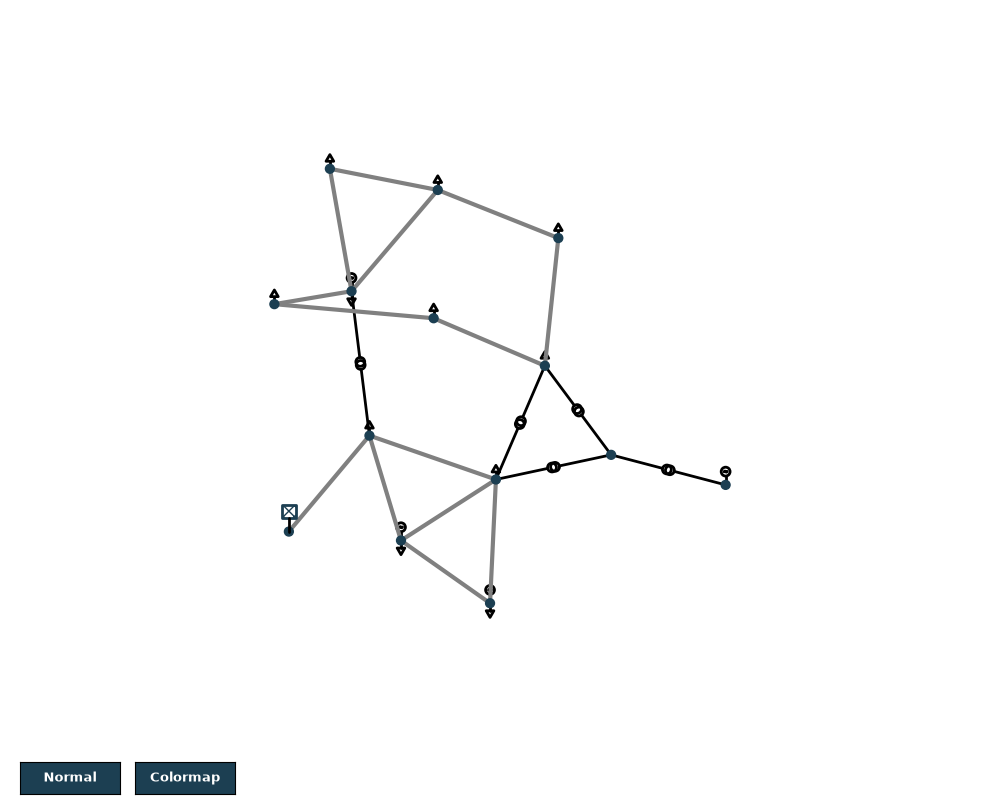

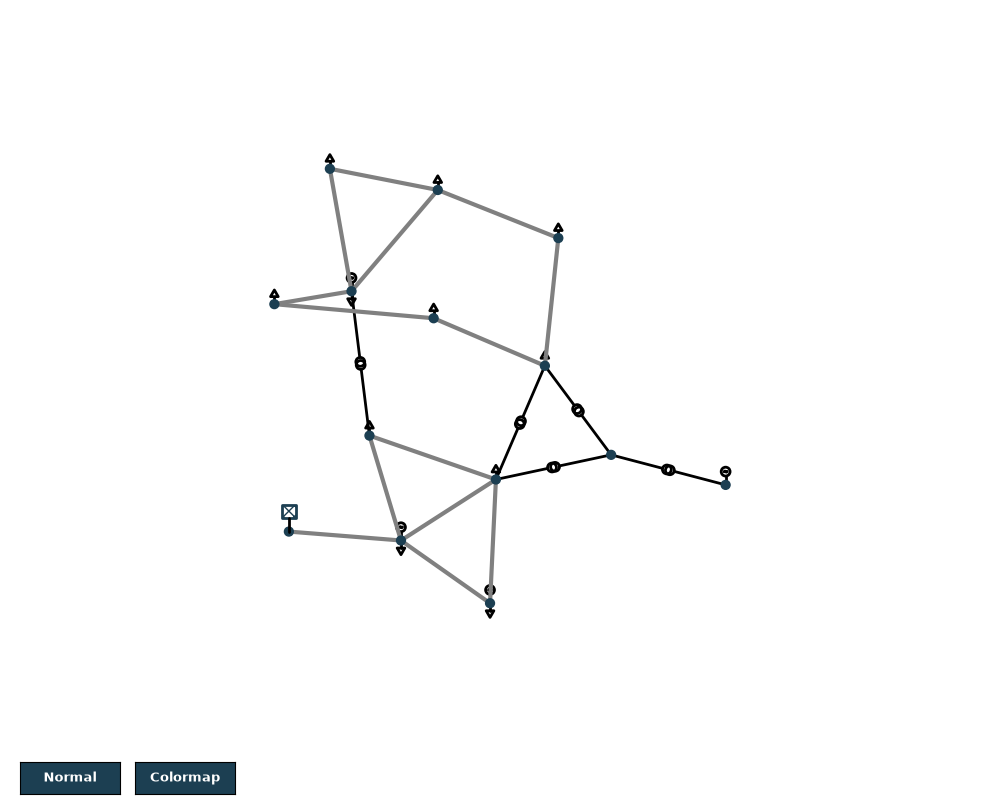

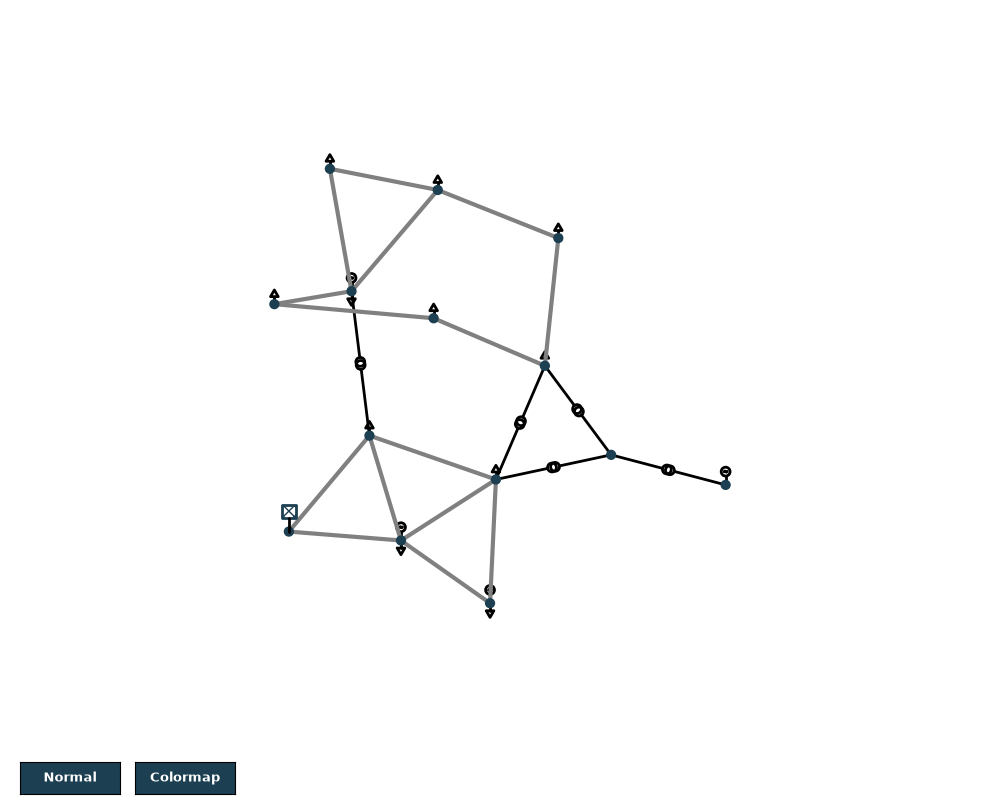

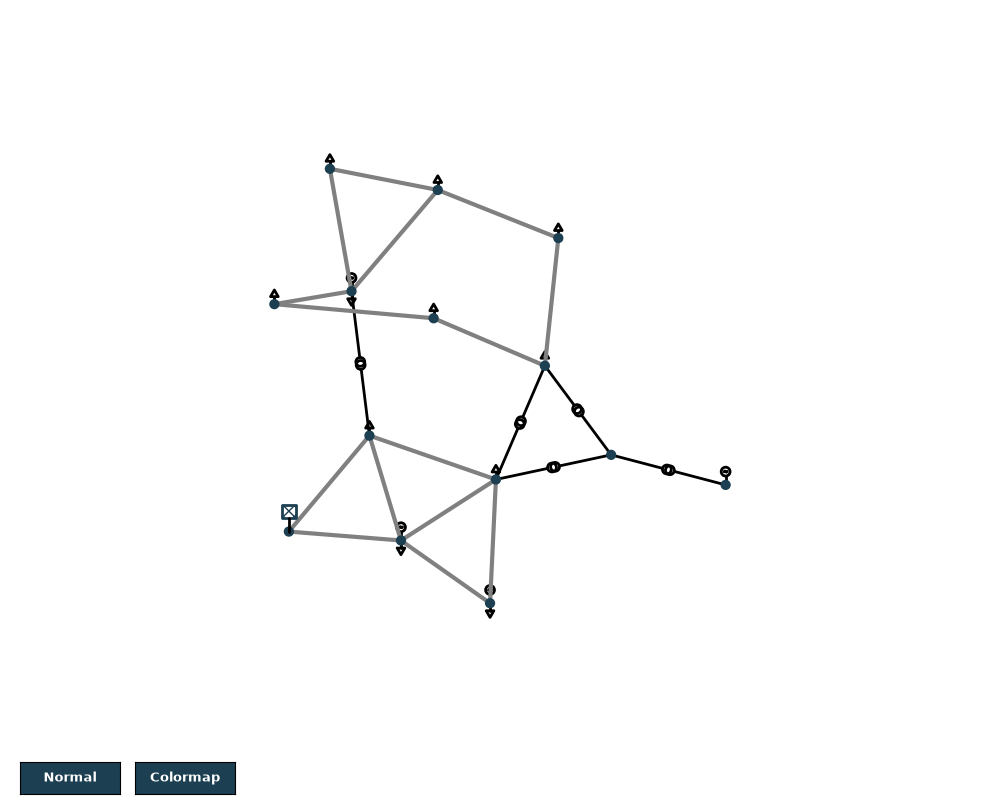

In [88]:
# generate network diagram
for elem, i in zip(cascade_starts["Element"], cascade_starts["Index"]):
    n = copy.deepcopy(net)
    getattr(n, elem).loc[i, "in_service"] = False
    plot.simple_plot(n, plot_loads= True, plot_gens=True)

<comment>

Sort total PI from greatest to least to identify the most vulnerable elements.

In [89]:
first = ["Element", "Index"]
ordered = results[first + [col for col in results.columns if col not in first]]
display(ordered.sort_values(by="PI_Total", ascending=False).style.hide(axis="index"))

Element,Index,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total
trafo,2,Violation,117.375588,10,1,1.018114,1.068249,0,2.518151,5.343428,7.861579
line,0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241
line,11,Pass,97.222256,9,0,0.996870,1.065484,0,2.031903,2.431396,4.463299
line,6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432
trafo,0,Pass,79.234372,9,0,1.012978,1.068000,0,2.008663,2.310192,4.318855
line,1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485
line,2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291
trafo,4,Pass,83.686876,9,0,1.016938,1.067054,0,1.400587,2.427595,3.828182
line,5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746
line,10,Pass,66.601453,0,0,1.019030,1.065403,0,1.898760,1.892330,3.791089


Devise a strategy to mitigate the effects of vulnerable line outages.

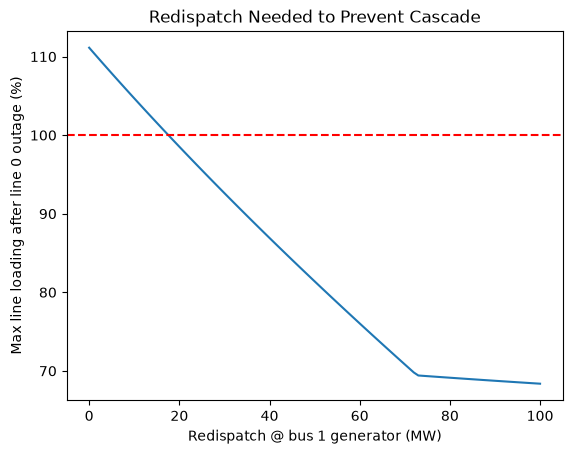

In [90]:
# redispatch: adjusting the power output of generators to keep the grid operating safely
def redispatch(net, redispatch_mw=0, gen_bus=1):
    n = copy.deepcopy(net)
    g = n.gen.index[n.gen.bus == gen_bus][0] # generator at bus 1
    n.gen.loc[g, "p_mw"] += redispatch_mw # boost power output
    return n

def outage_result(net, line):
    n = copy.deepcopy(net)
    n.line.loc[line, "in_service"] = False
    try:
        pp.runpp(n)
        return check_case(n)
    except pp.LoadflowNotConverged:
        return {
            "Status": "Non-convergence",
            "Max_Line_Loading_%": np.nan,
            }

rows = []
for mw in range(101):
    corrected = redispatch(net, redispatch_mw=mw)
    status = sim_cascade(corrected, load_max, 0)["Cascade_Status"]
    rows.append({"Redispatch_MW": mw, 
                 "Status": status,
                 "Max_Loading": outage_result(corrected, 0)["Max_Line_Loading_%"],
                 })

sweep = pd.DataFrame(rows)

plt.plot(sweep["Redispatch_MW"], sweep["Max_Loading"])
plt.title("Redispatch Needed to Prevent Cascade")
plt.xlabel("Redispatch @ bus 1 generator (MW)")
plt.ylabel("Max line loading after line 0 outage (%)")
plt.axhline(100, linestyle="--", color="red") # mark loading limit
plt.show()

In [91]:
# compare before and after 
def summary(mw):
    c = redispatch(net, mw)
    r = outage_result(c, 0)
    s = sim_cascade(c, load_max, 0)
    return {
        "Redispatch_MW": mw,
        "N1_Status": r["Status"],
        "Max _Line_Loading_%": round(r["Max_Line_Loading_%"], 1),
        "Worst_Line": r["Worst_Line"],
        "Cascade_Status": s["Cascade_Status"],
        "Lines_Tripped": s["Total_Tripped"],
        "Load_Lost_MW": round(s["Load_Lost_MW"], 1),
    }

first_stable = sweep.loc[sweep["Status"] == "Stable", "Redispatch_MW"].min()
comparison = pd.DataFrame([summary(0), summary(first_stable)], index=["Before", "After"]).T
display(comparison)

,Before,After
Redispatch_MW,0,18
N1_Status,Violation,Pass
Max _Line_Loading_%,111.1,99.7
Worst_Line,1,1
Cascade_Status,Blackout (islanded),Stable
Lines_Tripped,2,1
Load_Lost_MW,259.0,0.0


In [92]:
# load shedding: deliberate, temporary shutdown of electric supply to selected loads
shed_records = []

for load_id in net.load.index:
    n = copy.deepcopy(net)
    n.line.loc[0, "in_service"] = False # trip line 0 (N-1 case)
    n.load.loc[load_id, "in_service"] = False # shed a load
    try:
        pp.runpp(n)
        row = check_case(n) # reuse pass/violation check
    except pp.LoadflowNotConverged:
        row = {"Status": "Non-convergence", "Max_Line_Loading_%": np.nan}

    shed_only = copy.deepcopy(net)
    shed_only.load.loc[load_id, "in_service"] = False


    shed_records.append({
        "Shed_Bus": net.load.loc[load_id, "bus"],
        "Shed_Cost_MW": net.load.loc[load_id, "p_mw"],
        "Max_Line_Loading%": row["Max_Line_Loading_%"],
        "Fixes": row["Status"] == "Pass",
        "Cascade_Status": sim_cascade(shed_only, load_max, 0)["Cascade_Status"]
    })

# sort table based on fixes and shed cost
df_shed = (pd.DataFrame(shed_records)
           .sort_values(["Fixes", "Shed_Cost_MW"], ascending=[False, True])
           .reset_index(drop=True))
df_shed["Shed_%"] = 100 * df_shed["Shed_Cost_MW"] / net.load.p_mw.sum() # add shed % (~[shed cost/generated power]*100%)
display(df_shed.round(1).style.hide(axis="index"))


Shed_Bus,Shed_Cost_MW,Max_Line_Loading%,Fixes,Cascade_Status,Shed_%
1,21.700000,97.500000,True,Stable,8.400000
8,29.500000,92.800000,True,Stable,11.400000
3,47.800000,82.500000,True,Stable,18.500000
2,94.200000,67.400000,True,Stable,36.400000
10,3.500000,108.900000,False,Blackout (islanded),1.400000
11,6.100000,107.200000,False,Blackout (islanded),2.400000
4,7.600000,106.300000,False,Blackout (islanded),2.900000
9,9.000000,105.300000,False,Blackout (islanded),3.500000
5,11.200000,104.200000,False,Blackout (islanded),4.300000
12,13.500000,102.600000,False,Blackout (islanded),5.200000
